In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import scrublet as scr
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import glob

sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
plt.rcParams["figure.figsize"] = [6,6]
plt.rcParams["pdf.fonttype"] = 42 # add pdf text as one piece instead of letter by letter

In [2]:
import importlib.metadata as md
print(md.version("scrublet"))

0.2.3


In [3]:
sb.set_palette('colorblind')

In [4]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [5]:
# figure directory
fig_path = '/home/jovyan/mount/gdrive/HSC/chenqu_jhub/'
sc.settings.figdir = fig_path

# Download dataset

In [6]:
manifest = pd.read_csv('manifest/sample_manifest_01052026_manuscript.csv')
manifest = manifest.loc[manifest['screen_no'].isin(['1TF_2']),:]

In [7]:
smp_dict = ['6464STDY13747324']

In [8]:
# check whether all files have been downloaded in matrix folder - checked - all downloaded from new mapping cellranger 720
DATAFOLDER = '/nfs/team205/cs42/HSC_matrix/'
exist = [x.split('/')[-1] for x in glob.glob(DATAFOLDER+'*')]

if len([x for x in smp_dict if x not in exist])>0:
    print([smp_dict[x][2] for x in smp_dict if x not in exist],'not in matrix folder')

In [9]:
def read_files(filename, raw_file_path = '/nfs/team205/cs42/HSC_matrix/',
               min_n_count = 1000, min_n_gene = 500):

    
    path = '%s/%s/'%(raw_file_path,filename)
    adata = sc.read_10x_h5(path+'filtered_feature_bc_matrix.h5', gex_only=False)
    
    adata.obs_names = [filename+"-"+x.strip("-1") for x in adata.obs_names]
   
    # define mito & GEX
    gex = np.array(adata.var['feature_types']=='Gene Expression')
    mito_genes = np.array(adata.var_names.str.startswith('MT-')) & gex
    exog_genes = np.array(adata.var_names.str.startswith('EXOG_')) 
    # update gex to exclude exog_genes
    gex_update = gex & ~exog_genes
    
    antibody_capture = np.array(adata.var['feature_types']=='Antibody Capture')
    
    # caculate n_counts / n_genes per cell
    adata.obs['n_counts_GEX'] = np.sum(adata[:,gex_update].X, axis=1).A1
    adata.obs['n_genes'] = np.sum(adata[:,gex_update].X>0,axis=1)
    adata.obs['n_counts_antibody_capture'] = np.sum(adata[:,antibody_capture].X, axis=1).A1
    
    # calculate mito%
    adata.obs['mito'] = (np.sum(adata.X[:, mito_genes],axis=1).A1) / (np.sum(adata[:,gex_update].X,axis=1).A1)
    
    
    # filter cells
    clist = []
    clist.append(np.array(adata.obs['n_counts_GEX'] > 1000))
    clist.append(np.array(adata.obs['n_genes'] > 500))
    #clist.append(np.array(adata.obs['n_genes'] < 7000))
    clist.append(np.array(adata.obs['mito'] < 0.2)) # filter out mito >= 0.2
    
    c = np.column_stack(clist).all(axis=1)
    adata = adata[c].copy()
    
    # update manifest onto .obs
    adata.obs['file'] = filename
    adata.obs['sanger_sample_ID'] = manifest.loc[manifest['sequence_name']==filename, 'sanger_sample_ID'].item()
    adata.obs['screen_no'] = manifest.loc[manifest['sequence_name']==filename, 'screen_no'].item()
    adata.obs['Date_of_sample'] = manifest.loc[manifest['sequence_name']==filename, 'Date_of_sample'].item()
    adata.obs['HSC_days'] = manifest.loc[manifest['sequence_name']==filename, 'HSC days'].item()
    adata.obs['FACS_sort'] = manifest.loc[manifest['sequence_name']==filename, 'FACS_sort'].item()
    adata.obs['10x_kit'] = manifest.loc[manifest['sequence_name']==filename, '10x kit'].item()
    
    # calculate doublets using scrublet
    scrub = scr.Scrublet(adata.X)
    doublet_scores, predicted_doublets = scrub.scrub_doublets(verbose=False)
    adata.obs['doublet_scores'] = doublet_scores
    adata.obs['predicted_doublets'] = predicted_doublets
    
    sc.write('%s_filtered'%(filename),adata)

In [10]:
from multiprocessing import Pool

with Pool(10) as p:
    p.map(read_files, [x for x in smp_dict])

/home/jovyan/my-conda-envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1798: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/jovyan/my-conda-envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1798: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


# Merge dataset

In [11]:
ad = {}

In [12]:
for filename in smp_dict:
    ad[filename] = sc.read('%s_filtered'%(filename))
    ad[filename].var_names_make_unique()

/home/jovyan/my-conda-envs/myclone/lib/python3.11/site-packages/anndata/_core/anndata.py:1798: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [13]:
merged = None;
for key in ad: 
    if merged is None:
        merged = ad[key]
    else:
        merged = merged.concatenate(ad[key], join='outer')

In [14]:
Counter(merged.obs['file'])

Counter({'6464STDY13747324': 12986})

### Remove doublets

In [15]:
merged = merged[merged.obs['doublet_scores']<0.4]
merged = merged[merged.obs['predicted_doublets']==False]

In [16]:
Counter(merged.obs['file'])

Counter({'6464STDY13747324': 12908})

# Call exog_TF

In [17]:
exog_genes = merged.var_names[merged.var_names.str.startswith('EXOG_')]

In [18]:
print(exog_genes)

Index(['EXOG_EGFP', 'EXOG_PuroR', 'EXOG_Bxb1', 'EXOG_Bsd', 'EXOG_mApple',
       'EXOG_GFI1B', 'EXOG_GFI1', 'EXOG_HLF', 'EXOG_IKZF1', 'EXOG_IRF5',
       'EXOG_MYB_CON', 'EXOG_MYCN', 'EXOG_NFE2', 'EXOG_RUNX1',
       'EXOG_SP100variant1', 'EXOG_SPI1', 'EXOG_TFEC', 'EXOG_BCL11Avariant1'],
      dtype='object')


## Exog_TF calling

In [19]:
exog_exception = ['EXOG_mApple','EXOG_Bsd', 'EXOG_Bxb1','EXOG_PuroR']
exog_genes_count = [gene for gene in exog_genes if gene not in exog_exception]

In [20]:
# Convert to CSR for efficient row-wise operations
X = merged[:, exog_genes_count].X.tocsr()

# Compute row-wise max and sum
row_max = X.max(axis=1).toarray().ravel()
row_sum = X.sum(axis=1).A1  

merged.obs['TF_max_count'] = row_max
# TF_calling based on which exogenous TF has the highest count
merged.obs['TF_calling'] = pd.Index(exog_genes_count)[np.argmax(np.array(merged[:,exog_genes_count].X.todense()),axis=1)]

# compute the fraction of the dominant barcode
with np.errstate(divide='ignore', invalid='ignore'):
    merged.obs['TF_max_perc'] = np.divide(row_max, row_sum, out=np.zeros_like(row_max), where=row_sum != 0)

/tmp/ipykernel_1149/932948815.py:8: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  merged.obs['TF_max_count'] = row_max


/tmp/ipykernel_1149/102091084.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sb.barplot(


Text(0, 0.5, 'number of cells')

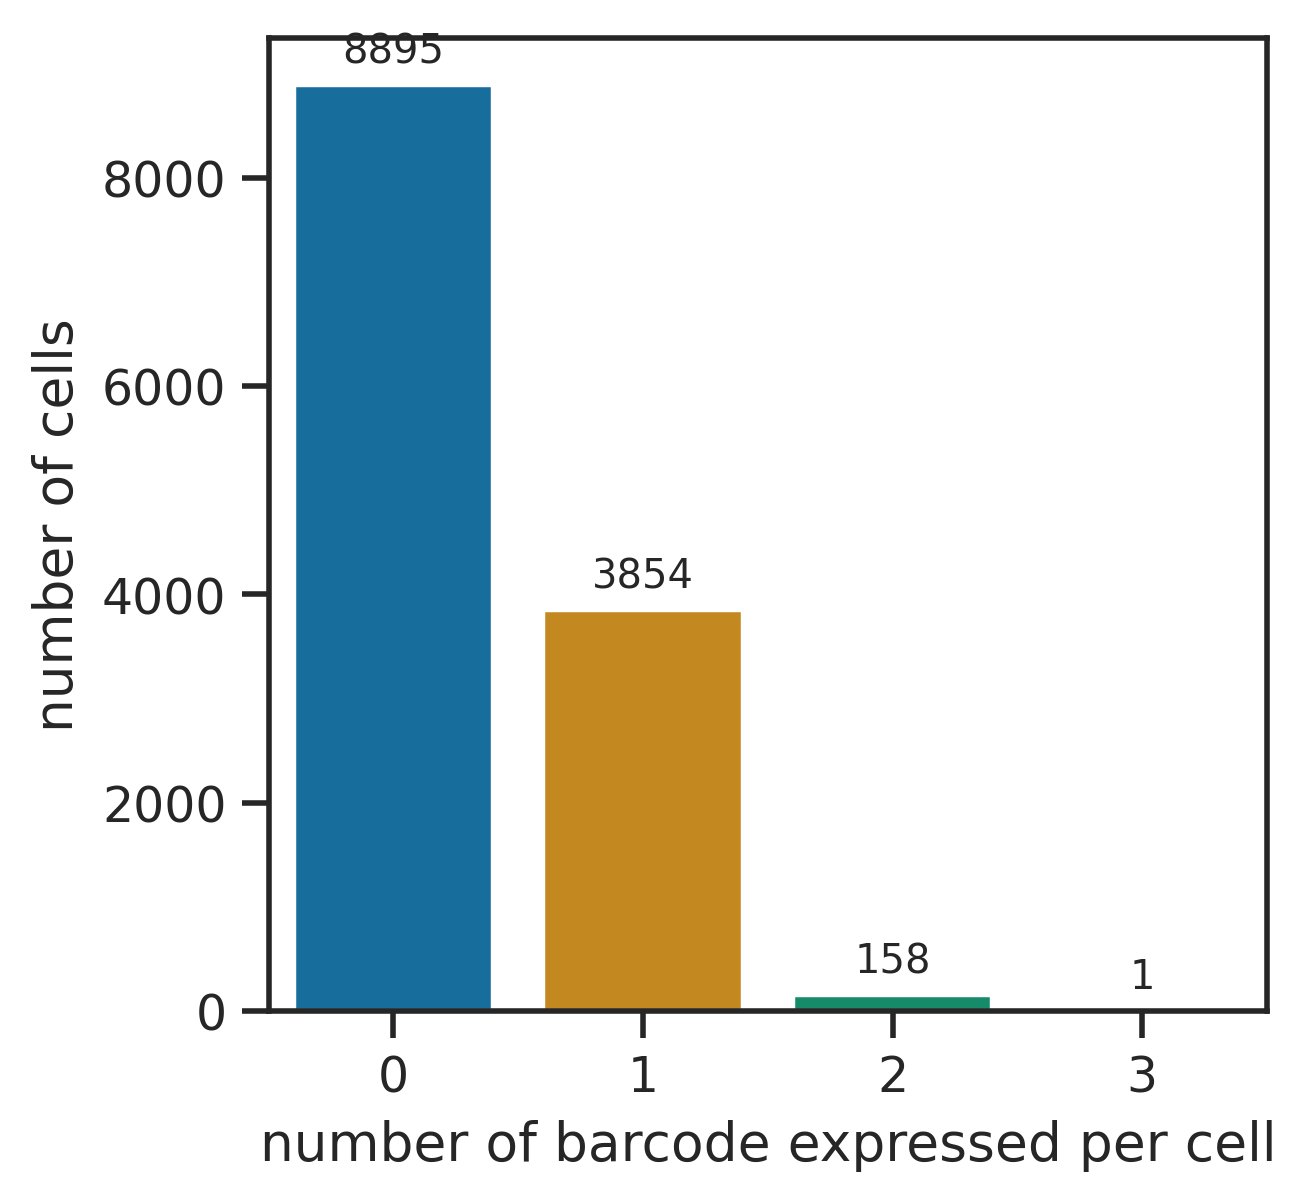

In [21]:
# seaborn theme
sb.set_theme(style="ticks")

# compute number of barcodes expressed per cell
data = np.array((X > 0).sum(axis=1)).flatten()

# count cells per barcode number
df = (
    pd.Series(data, name="n_barcode_expressed")
      .value_counts()
      .sort_index()
      .reset_index()
)
df.columns = ["n_barcode_expressed", "n_cell"]

# plot
plt.figure(figsize=(4, 4))
ax = sb.barplot(
    data=df,
    x="n_barcode_expressed",
    y="n_cell",
    palette="colorblind"   # different color for each bar
)


# add counts on top of bars
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"{int(height)}",
        (p.get_x() + p.get_width() / 2., height),
        ha="center",
        va="bottom",
        fontsize=9,
        xytext=(0, 3),
        textcoords="offset points"
    )

# axis formatting
#ax.set_xlim(0.5,4.5)  
#ax.set_ylim(0,8000)
ax.set_xlabel("number of barcode expressed per cell")
ax.set_ylabel("number of cells")

#plt.savefig(fig_path+"first_screen_cell_barcode_histogram.pdf", bbox_inches='tight')

Text(0, 0.5, 'number of cells')

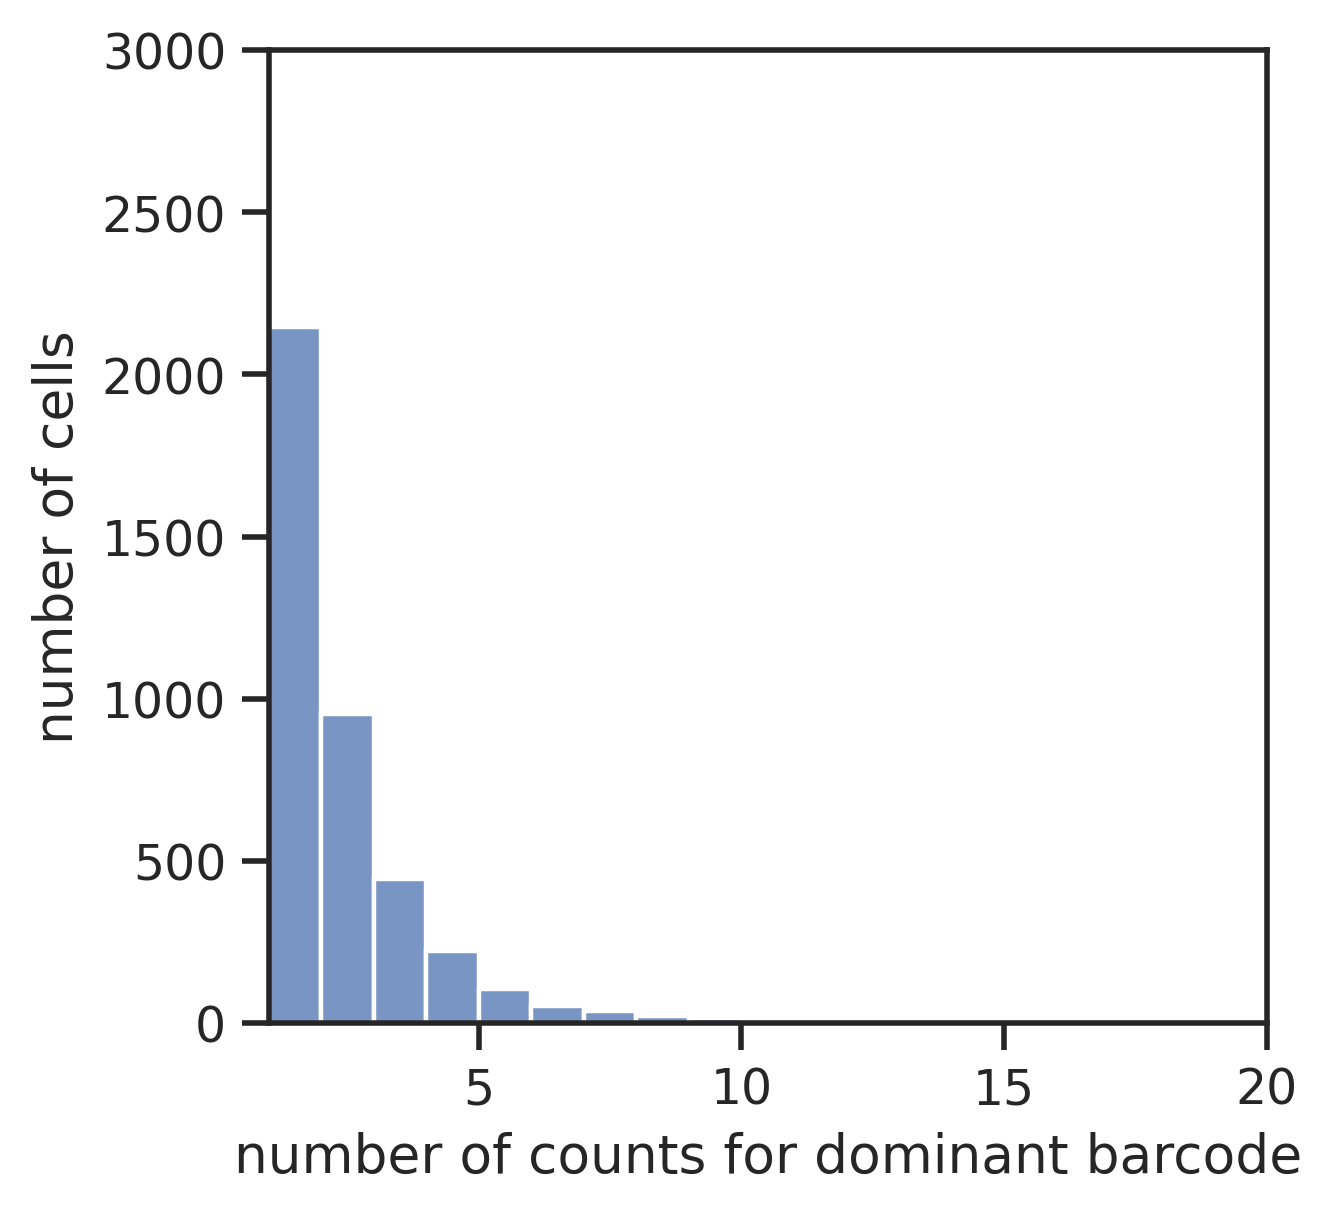

In [34]:
# How many barcodes does each cell express
plt.rcParams["figure.figsize"] = [4,4]
sb.histplot(merged.obs['TF_max_count'],binwidth=1)
plt.xlim(1, 20)
plt.ylim(0,3000)
plt.xlabel("number of counts for dominant barcode")         # X-axis label
plt.ylabel("number of cells")   # Y-axis label
#plt.title("Distribution of number of barcodes expressed each cell")
#plt.savefig(fig_path+"first_screen_dominant_barcode_count_histogram.pdf", bbox_inches='tight')

Text(0, 0.5, 'n_cell')

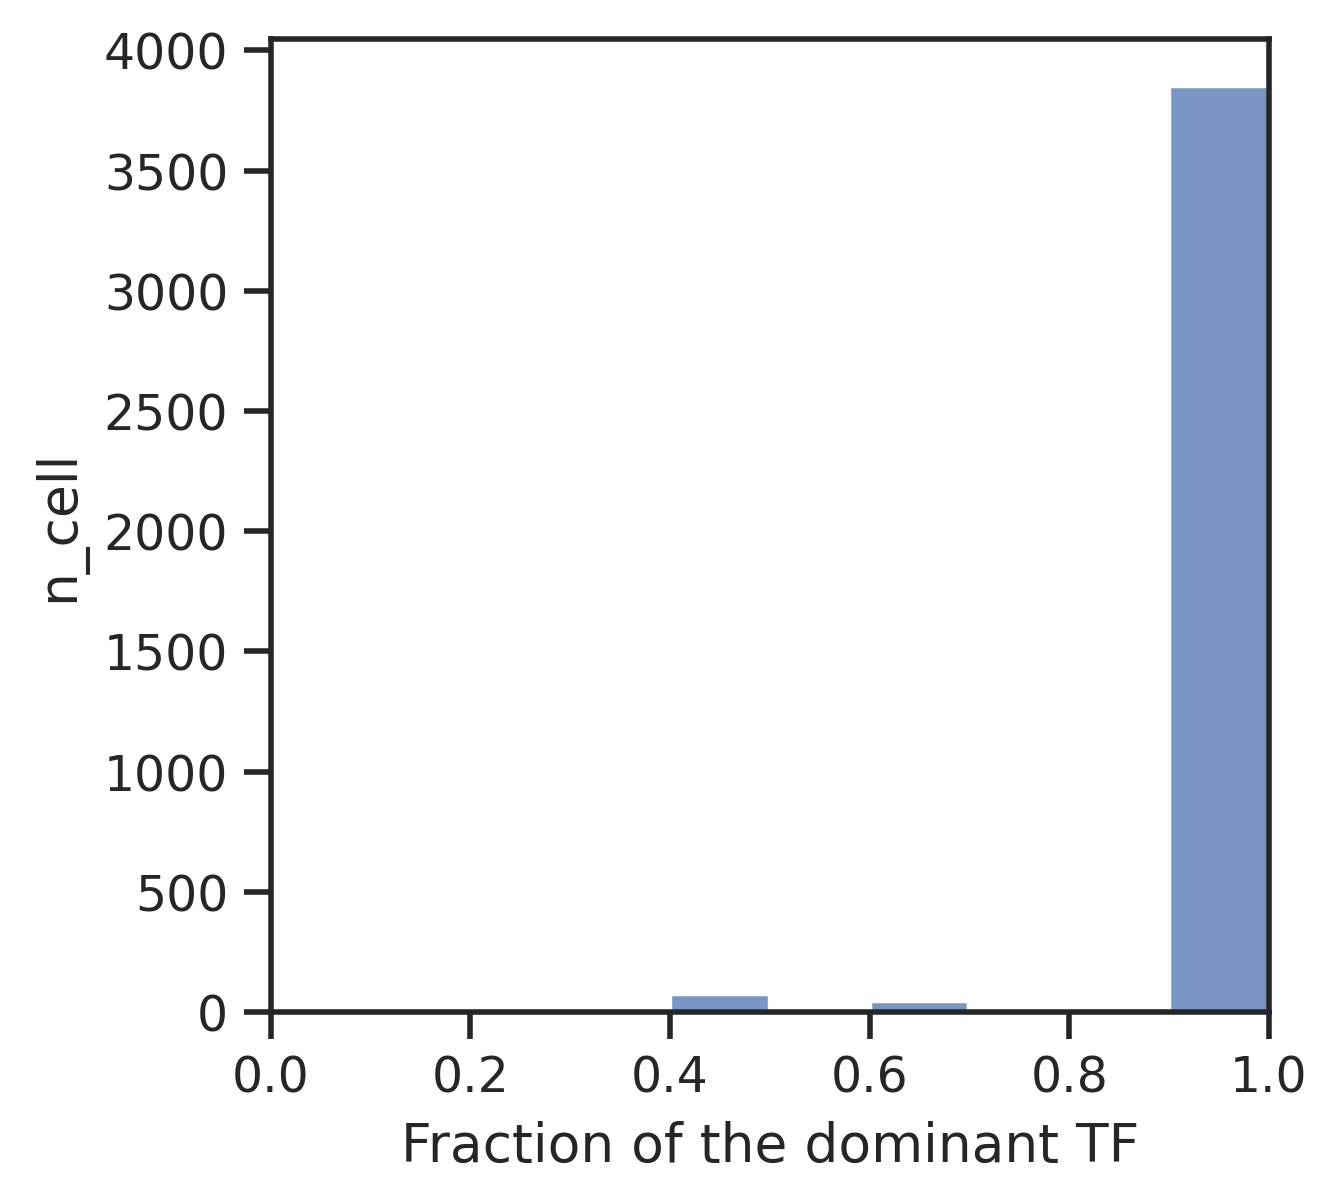

In [23]:
# How many barcodes does each cell express
plt.rcParams["figure.figsize"] = [4,4]
#sb.histplot(merged_cite.obs.loc[merged_cite.obs['antibody_max_count'] >0,'antibody_max_perc'],binwidth=0.1)
sb.histplot(merged.obs.loc[merged.obs['TF_max_perc']>0,'TF_max_perc'],binwidth=0.1)
plt.xlim(0, 1)
plt.xlabel("Fraction of the dominant TF")         # X-axis label
plt.ylabel("n_cell")   # Y-axis label
#plt.title("Distribution of number of barcodes expressed each cell")
#plt.savefig("figure/max_antibody_barcode_fraction_histogram.png", dpi=300, bbox_inches='tight')

In [24]:
# if max percentage =< 0.5, remove the antibody calling - mainly to avoid the case where there are 2 counts, 1 from each different TF
merged.obs.loc[merged.obs['TF_max_perc'] <= 0.5,'TF_calling'] = np.nan

In [25]:
pd.crosstab(merged.obs['TF_calling'], merged.obs['sanger_sample_ID'])

sanger_sample_ID,HSC_HET_1TF_D18_noCYTO single TFs
TF_calling,
EXOG_EGFP,2
EXOG_GFI1,347
EXOG_GFI1B,1188
EXOG_HLF,979
EXOG_NFE2,1192
EXOG_SPI1,229


Now remove the exogenous genes from adata.var before log-normalisation 

In [26]:
gene_remove = list(exog_genes)

In [27]:
# only leave GEX genes for downstream
merged = merged[:,~merged.var_names.isin(gene_remove)]

In [28]:
merged = merged.copy()

In [29]:
merged.write_h5ad('write/SPI1_CONSTITUTIVE_selected_data_raw_count.h5ad')

## Preprocessing - normalise and log

In [30]:
merged = sc.read('write/SPI1_CONSTITUTIVE_selected_data_raw_count.h5ad')

In [31]:
sc.pp.normalize_per_cell(merged,counts_per_cell_after=1e4,key_n_counts='n_counts_GEX')

/tmp/ipykernel_1149/1240904363.py:1: FutureWarning: Use sc.pp.normalize_total instead
  sc.pp.normalize_per_cell(merged,counts_per_cell_after=1e4,key_n_counts='n_counts_GEX')
/home/jovyan/my-conda-envs/myclone/lib/python3.11/site-packages/scanpy/preprocessing/_simple.py:590: FutureWarning: Use sc.pp.normalize_total instead
  normalize_per_cell(


In [32]:
sc.pp.log1p(merged)

In [33]:
merged.write_h5ad('write/SPI1_CONSTITUTIVE_selected_data_normalised_log.h5ad')